# E18 - replication of the background contrast on 12 new briefs

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-12<br>
**Pipeline stage**: experiment - registered batch `E18`, notebook B, hypotheses `E18-H88`, `E18-H89`, `E18-H90`, `E18-H92`<br>
**Execution model**: session model (one executor agent for the notebook, one independent verifier)

**Purpose** - measure whether the background contrast of `E17-H85` (nearest cost to the brief minus its mean over other briefs) raises the AUC on 12 briefs that were not scored before (`E18-H88`), how few background briefs are needed (`E18-H89`), whether an exact Otsu split of the contrast marks match and no match (`E18-H90`), and whether the report against itself can stand in for the other briefs (`E18-H92`).

**Terms used below**

- **baseline** - `b_i = min_j c_ij`, the nearest ground cost of report statement `i` over the brief statements `j`, with `c = cost_matrix(E_report, E_brief)`; lower means more relevant
- **contrast** - `b_i` of the brief minus the mean of `b_i` over background briefs; lower means more relevant; the relevance score is its negative
- **AUC** - the probability that a random positive statement has a higher relevance score than a random negative one, ties count one half
- **positive / negative / neutral** - for a brief, the statements of its target sections / all other scored statements / the statements of `Key findings` and `Overview`, which are left out of every metric
- **new briefs** - `brief-13` to `brief-24` (the headline set, every bar is read on them); **seen briefs** - `brief-01` to `brief-12`, scored in `E17`, readings on them carry no bar
- **control** - one of the 7 summaries of the ibm article; positives are the statements of part 1, negatives those of part 2

Nothing under `src/`, `tests/`, `docs/` or the fixture is edited. Every bar is the registered one and is applied as written.

## Cells copied from the template

The template is `notebooks/experiments/E17-kj-relevance-map.ipynb`. Copied without a change of logic: the environment cell, the imports, the reading cell (one `DocDistance()`, default reader, `embed_statements`, the `section` field of the `flows` of `semantic_distance_with_details`, report first), the labels cell (leaf, part, neutral sections, part-level labels for controls), `auc` (Mann-Whitney, ties one half), the bootstrap (10000 resamples, seed 0, reported), `section_reading` (top 2), `otsu_threshold` and `balanced_accuracy`. New in this notebook: the second label file, the background scores, the draws of `E18-H89`, the self-background of `E18-H92` and the decision cells.

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 CPU path. Models resolve offline from the local cache; `DOCDISTANCE_HOME` is pinned to the repository root.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["CI"] = "true"                          # disables OpenVINO telemetry
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"   # docdistance.json lives at the repo root

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline, DOCDISTANCE_HOME pinned")

environment set: CPU only, models offline, DOCDISTANCE_HOME pinned


## Imports

The shipped `docdistance` core is imported and never edited.

In [2]:
# Standard library
import contextlib                      # silence the model-load stderr output
import hashlib                         # sha256 of the fixture files
import io                              # sink for the redirected stderr
import json                            # labels, registration and metrics JSON
import platform                        # python version
import time                            # wall time and the write stamp
from datetime import datetime, timezone
from pathlib import Path               # fixture paths

# Scientific
import numpy as np                     # arrays
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.stats import rankdata       # average ranks for the Mann-Whitney AUC

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console
from rich.console import Console
from rich.markup import escape
from rich.table import Table

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import cost_matrix                          # ground cost sqrt(2 - 2cos)
from docdistance.pipeline import DIFF_CHANGED_COST, DocDistance       # shipped reader, segmenter, encoder; fixed cutoff

%matplotlib inline
console = Console(width=200, highlight=False)
T_START = time.time()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | python {platform.python_version()}")

docdistance 1.1.32 | POT 0.9.6.post1 | numpy 2.4.6 | python 3.14.8


## Reproducibility

Segmentation, the INT8 encode and the cost matrix are deterministic. One seed drives the bootstrap and, as a separate generator, the draws of `E18-H89`.

In [3]:
SEED = 0
print(f"SEED = {SEED}")

SEED = 0


## Configuration

Every path, constant and bar of the notebook is set in the next cell. The fixture hash check runs here: every file of the registration must equal its stored sha256.

In [4]:
ROOT = Path(os.environ["DOCDISTANCE_HOME"])
FIXTURE = ROOT / "data/processed/relevance-fixture"
E18_FIXTURE = FIXTURE / "e18"
REGISTRATION = ROOT / "reports/E18-relevance/E18-relevance-registration.json"
E17_METRICS_FILE = ROOT / "reports/E17-relevance-map-metrics.json"
METRICS_FILE = ROOT / "reports/E18-contrast-replication-metrics.json"

BATCH_GATE_AUC = 0.95                  # baseline mean AUC over briefs 13 to 24 at or above this kills H88, H89, H92 at the gate
BAR_GAIN = 0.03                        # mean AUC difference to the baseline
BAR_COUNT = 10                         # briefs (of 12) with a difference above 0
BAR_CONTROL_DROP = 0.01                # control mean AUC may fall by at most this
H90_GATE_BA = 0.65                     # fixed-cutoff mean balanced accuracy at or above this kills H90 at the gate
H90_BAR_BA = 0.70                      # Otsu mean balanced accuracy must reach this
H90_BAR_GAIN = 0.10                    # and exceed the fixed cutoff's by this
H89_KS = (1, 2, 3, 5)                  # background sizes
H89_BAR_K = 3                          # the k at which the bar is read
H89_DRAWS = 200                        # draws per brief and k
HARNESS_TOL = 1e-9                     # absolute difference allowed against the E17 metrics
N_BOOT = 10000                         # bootstrap resamples of the mean difference (reported, no bar)
TOP_N_SECTIONS = 2                     # section-reading top rank

LABELS17 = json.loads((FIXTURE / "labels.json").read_text(encoding="utf-8"))
LABELS18 = json.loads((E18_FIXTURE / "labels.json").read_text(encoding="utf-8"))
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
E17M = json.loads(E17_METRICS_FILE.read_text(encoding="utf-8"))
NEUTRAL = LABELS17["neutral_sections"]
PARTS = LABELS17["parts"]
assert NEUTRAL == LABELS18["neutral_sections"] and PARTS == LABELS18["parts"], "the two label files differ in parts or neutral sections"
OLD_IDS = sorted(LABELS17["briefs"])
NEW_IDS = sorted(LABELS18["briefs"])
ALL_IDS = NEW_IDS + OLD_IDS
CONTROL_IDS = list(LABELS17["controls"])
assert OLD_IDS == [f"brief-{i:02d}" for i in range(1, 13)] and NEW_IDS == [f"brief-{i:02d}" for i in range(13, 25)]
assert list(LABELS18["controls"]) == CONTROL_IDS
for cid in CONTROL_IDS:
    assert (FIXTURE / LABELS17["controls"][cid]["file"]).resolve() == (E18_FIXTURE / LABELS18["controls"][cid]["file"]).resolve(), f"control {cid} differs between the label files"

fixture_sha = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in REG["fixture_sha256"]}
assert fixture_sha == REG["fixture_sha256"], "fixture differs from the registration"

table = Table(title="Configuration", show_lines=False)
table.add_column("item"); table.add_column("value")
for key, value in [
    ("fixture", FIXTURE.relative_to(ROOT)), ("new briefs / seen briefs / controls", f"{len(NEW_IDS)} / {len(OLD_IDS)} / {len(CONTROL_IDS)}"),
    ("neutral sections", NEUTRAL), ("parts", PARTS), ("DIFF_CHANGED_COST (fixed cutoff)", DIFF_CHANGED_COST),
    ("batch gate", f"baseline mean AUC over briefs 13 to 24 >= {BATCH_GATE_AUC} kills H88, H89, H92"),
    ("bar H88 / H92", f"mean diff >= {BAR_GAIN}, diff > 0 in >= {BAR_COUNT} of 12, control mean AUC drop <= {BAR_CONTROL_DROP}"),
    ("bar H89", f"at k = {H89_BAR_K}: mean diff >= {BAR_GAIN} and diff > 0 in >= {BAR_COUNT} of 12; {H89_DRAWS} draws, k in {H89_KS}, default_rng({SEED})"),
    ("gate / bar H90", f"fixed-cutoff BA >= {H90_GATE_BA} kills; Otsu BA >= {H90_BAR_BA} and >= {H90_BAR_GAIN} above fixed"),
    ("harness tolerance", f"{HARNESS_TOL}"), ("bootstrap", f"{N_BOOT} resamples, seed {SEED} (reported, no bar)"),
    ("fixture sha256", f"all {len(fixture_sha)} files equal the registration"),
]:
    table.add_row(str(key), str(value))
console.print(table)

                                                                        Configuration                                                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ item                                ┃ value                                                                                                               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture                             │ data/processed/relevance-fixture                                                                                    │
│ new briefs / seen briefs / controls │ 12 / 12 / 7                                                                                                         │
│ neutral sections                    │ ['Key findings', 'Overview']                                                                                        │
│ parts                               │ {'ibm': 'Part 1 - Enterprise adoption of AI', 'wergeland': 'Part 2 - Impact of artificial intelligence on society'} │
│ DIFF_CHANGED_COST (fixed cutoff)    │ 0.3252691193458119                                                                                                  │
│ batch gate                          │ baseline mean AUC over briefs 13 to 24 >= 0.95 kills H88, H89, H92                                                  │
│ bar H88 / H92                       │ mean diff >= 0.03, diff > 0 in >= 10 of 12, control mean AUC drop <= 0.01                                           │
│ bar H89                             │ at k = 3: mean diff >= 0.03 and diff > 0 in >= 10 of 12; 200 draws, k in (1, 2, 3, 5), default_rng(0)               │
│ gate / bar H90                      │ fixed-cutoff BA >= 0.65 kills; Otsu BA >= 0.7 and >= 0.1 above fixed                                                │
│ harness tolerance                   │ 1e-09                                                                                                               │
│ bootstrap                           │ 10000 resamples, seed 0 (reported, no bar)                                                                          │
│ fixture sha256                      │ all 16 files equal the registration                                                                                 │
└─────────────────────────────────────┴─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

## Reading

One `DocDistance()` with the shipped defaults. The report is the first document of `semantic_distance_with_details`, so the `section` field of its `flows` gives the section path of every report statement. Briefs of both sets and the 7 controls are encoded by `embed_statements`.

In [5]:
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance()
    report_path = FIXTURE / LABELS17["report"]
    assert (E18_FIXTURE / LABELS18["report"]).resolve() == report_path.resolve()
    R_TEXTS, E_R = dd.embed_statements(report_path)
    first_brief = FIXTURE / LABELS17["briefs"][OLD_IDS[0]]["file"]
    _, DETAIL = dd.semantic_distance_with_details(report_path, first_brief)
    BRIEF_TEXTS, E_BRIEF = {}, {}
    for bid in OLD_IDS:
        BRIEF_TEXTS[bid], E_BRIEF[bid] = dd.embed_statements(FIXTURE / LABELS17["briefs"][bid]["file"])
    for bid in NEW_IDS:
        BRIEF_TEXTS[bid], E_BRIEF[bid] = dd.embed_statements(E18_FIXTURE / LABELS18["briefs"][bid]["file"])
    CONTROL_TEXTS, E_CONTROL = {}, {}
    for cid in CONTROL_IDS:
        CONTROL_TEXTS[cid], E_CONTROL[cid] = dd.embed_statements((FIXTURE / LABELS17["controls"][cid]["file"]).resolve())

FLOWS = DETAIL["flows"]
assert [f["text"] for f in FLOWS] == R_TEXTS, "flow texts differ from the report statements"
SECTION_PATH = [f["section"] for f in FLOWS]
assert all(SECTION_PATH), "a report statement has no section"
LEAF = np.array([p.split(" > ")[-1] for p in SECTION_PATH])
PART = np.array([p.split(" > ")[0] for p in SECTION_PATH])
N_REPORT = len(R_TEXTS)
assert N_REPORT == 93, f"the report holds {N_REPORT} statements, not 93"

counts = {}
for path in SECTION_PATH:
    counts[path] = counts.get(path, 0) + 1
console.print(escape(f"report {N_REPORT} statements in {len(counts)} distinct section values; part names found: {sorted(set(PART))}"))
console.print("new briefs " + ", ".join(f"{b[-2:]}: {len(BRIEF_TEXTS[b])}" for b in NEW_IDS))
console.print("seen briefs " + ", ".join(f"{b[-2:]}: {len(BRIEF_TEXTS[b])}" for b in OLD_IDS))
console.print("controls " + ", ".join(f"{c}: {len(CONTROL_TEXTS[c])}" for c in CONTROL_IDS))

report 93 statements in 18 distinct section values; part names found: [np.str_('Part 1 - Enterprise adoption of AI'), np.str_('Part 2 - Impact of artificial intelligence on society')]

new briefs 13: 5, 14: 5, 15: 6, 16: 4, 17: 8, 18: 5, 19: 7, 20: 5, 21: 6, 22: 6, 23: 10, 24: 6

seen briefs 01: 6, 02: 6, 03: 6, 04: 6, 05: 6, 06: 6, 07: 6, 08: 6, 09: 6, 10: 6, 11: 6, 12: 6

controls gold: 10, gold-2: 12, v1: 11, v2: 11, opus: 12, sonnet: 10, haiku: 13

## Labels

For a brief, positives are the report statements whose leaf section is a target section of the brief, neutral sections are left out, every other statement is a negative. For a control, positives are the statements of part 1 and negatives those of part 2.

In [6]:
PART_NAMES = set(PARTS.values())
assert set(PART) <= PART_NAMES, "a statement sits under an unknown part"
IS_NEUTRAL = np.isin(LEAF, NEUTRAL)
assert IS_NEUTRAL.sum() > 0

LAB = {}
for bid in ALL_IDS:
    spec = (LABELS18 if bid in NEW_IDS else LABELS17)["briefs"][bid]
    for name in spec["target_sections"]:
        assert (LEAF == name).any(), f"{bid}: target section {name!r} matches no statement"
    pos = np.isin(LEAF, spec["target_sections"])
    assert not (pos & IS_NEUTRAL).any()
    assert (PART[pos] == PARTS[spec["part"]]).all(), f"{bid}: target outside the stated part"
    neg = ~pos & ~IS_NEUTRAL
    LAB[bid] = {"pos": pos, "neg": neg, "targets": spec["target_sections"]}

for cid in CONTROL_IDS:
    spec = LABELS17["controls"][cid]
    LAB[cid] = {"pos": PART == PARTS[spec["positive_part"]], "neg": PART != PARTS[spec["positive_part"]], "targets": None}

table = Table(title="Label counts")
for col in ("query", "positives", "negatives", "neutral", "target sections"):
    table.add_column(col)
for qid, lab in LAB.items():
    table.add_row(qid, str(lab["pos"].sum()), str(lab["neg"].sum()), str(IS_NEUTRAL.sum()) if lab["targets"] is not None else "0", "; ".join(lab["targets"]) if lab["targets"] else "part 1")
console.print(table)

                                                                           Label counts                                                                            
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ query    ┃ positives ┃ negatives ┃ neutral ┃ target sections                                                                                                    ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ brief-13 │ 4         │ 76        │ 13      │ Workforce impact                                                                                                   │
│ brief-14 │ 3         │ 77        │ 13      │ Trustworthy and governed AI                                                                                        │
│ brief-15 │ 4         │ 76        │ 13      │ Most companies have accelerated rollout in the past 24 months                                                      │
│ brief-16 │ 5         │ 75        │ 13      │ Adoption has remained steady at large organizations                                                                │
│ brief-17 │ 5         │ 75        │ 13      │ AI use cases cut across business operations; Easier tools and cost reduction are driving adoption                  │
│ brief-18 │ 4         │ 76        │ 13      │ About IBM                                                                                                          │
│ brief-19 │ 3         │ 77        │ 13      │ Barriers keeping the next wave from benefiting                                                                     │
│ brief-20 │ 4         │ 76        │ 13      │ Methodology                                                                                                        │
│ brief-21 │ 7         │ 73        │ 13      │ Teaching the topic                                                                                                 │
│ brief-22 │ 8         │ 72        │ 13      │ Bias and data                                                                                                      │
│ brief-23 │ 15        │ 65        │ 13      │ Future                                                                                                             │
│ brief-24 │ 20        │ 60        │ 13      │ AI in Society; Bias and data                                                                                       │
│ brief-01 │ 3         │ 77        │ 13      │ Barriers keeping the next wave from benefiting                                                                     │
│ brief-02 │ 4         │ 76        │ 13      │ Workforce impact                                                                                                   │
│ brief-03 │ 3         │ 77        │ 13      │ Trustworthy and governed AI                                                                                        │
│ brief-04 │ 3         │ 77        │ 13      │ Easier tools and cost reduction are driving adoption                                                               │
│ brief-05 │ 2         │ 78        │ 13      │ AI use cases cut across business operations                                                                        │
│ brief-06 │ 9         │ 71        │ 13      │ Adoption has remained steady at large organizations; Most companies have accelerated rollout in the past 24 months │
│ brief-07 │ 4         │ 76        │ 13      │ Methodology                                                                                                        │
│ brief-08 │ 6         │ 74        │ 13      │ Barriers keeping the next wave from benefiting; Trustworthy and governed AI                                        │
│ brief-09 │ 7         │ 73        │ 13      │ Teaching the topi

## Baseline and metric functions

The baseline `b_i` is the row minimum of the cost matrix of the report against the query. The AUC is the Mann-Whitney statistic from average ranks, so ties count one half.

In [7]:
QUERY_E = {**E_BRIEF, **E_CONTROL}
QUERY_IDS = ALL_IDS + CONTROL_IDS
BASE_COST = {qid: cost_matrix(E_R, QUERY_E[qid]).astype(np.float64).min(axis=1) for qid in QUERY_IDS}


def auc(score, pos, neg):
    "Mann-Whitney AUC of a relevance score for positives against negatives; ties count one half"
    ranks = rankdata(np.concatenate([score[pos], score[neg]]))
    n_pos, n_neg = int(pos.sum()), int(neg.sum())
    return float((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def auc_of(score, qid):
    return auc(score, LAB[qid]["pos"], LAB[qid]["neg"])


def contrast_score(qid, background_ids):
    "Relevance score of the contrast: minus (b_i of the query minus the mean b_i over the background briefs)"
    return -(BASE_COST[qid] - np.mean([BASE_COST[b] for b in background_ids], axis=0))


def otsu_threshold(values):
    "Exact Otsu split of a sample: the midpoint between neighbouring distinct sorted values with the largest between-class variance"
    v = np.sort(values)
    distinct = np.unique(v)
    best_var, best_t = -1.0, None
    for t in (distinct[:-1] + distinct[1:]) / 2:
        lo, hi = v[v <= t], v[v > t]
        var = (len(lo) / len(v)) * (len(hi) / len(v)) * (lo.mean() - hi.mean()) ** 2
        if var > best_var:                       # strict: an exact tie keeps the lower threshold
            best_var, best_t = var, float(t)
    return best_t


def balanced_accuracy(match, pos, neg):
    "Mean of the recall on positives (match) and the recall on negatives (no match)"
    return float((match[pos].mean() + (~match[neg]).mean()) / 2)


def section_reading(score, bid):
    "Leaf sections (neutral left out) ranked from most to least relevant by mean score; share of targets in the top 2"
    leaves = [s for s in dict.fromkeys(LEAF) if s not in NEUTRAL]
    means = [float(score[LEAF == s].mean()) for s in leaves]
    ranked = [leaves[i] for i in np.argsort(-np.array(means), kind="stable")]
    targets = LAB[bid]["targets"]
    return ranked, sum(t in ranked[:TOP_N_SECTIONS] for t in targets) / len(targets)


print(f"baseline nearest costs computed for {len(QUERY_IDS)} queries")

baseline nearest costs computed for 31 queries


## Harness check

Before any new brief is scored, the copied cells must reproduce the baseline AUC and the `E17-H85` AUC of briefs 01 to 12 stored in `reports/E17-relevance-map-metrics.json`, each with an absolute difference below 1e-9. The `E17-H85` score of a seen brief has the other 11 seen briefs as the background. The 7 controls are compared as well and reported. A failed check stops the run.

In [8]:
HARNESS = {}
for bid in OLD_IDS:
    base = auc_of(-BASE_COST[bid], bid)
    h85 = auc_of(contrast_score(bid, [b for b in OLD_IDS if b != bid]), bid)
    HARNESS[bid] = {"baseline": {"now": base, "stored": E17M["auc_per_brief"][bid]["baseline"]}, "H85": {"now": h85, "stored": E17M["auc_per_brief"][bid]["H85"]}}
control_check = {}
for cid in CONTROL_IDS:
    base = auc_of(-BASE_COST[cid], cid)
    h85 = auc_of(contrast_score(cid, OLD_IDS), cid)
    control_check[cid] = {"baseline": abs(base - E17M["auc_per_control"][cid]["baseline"]), "H85": abs(h85 - E17M["auc_per_control"][cid]["H85"])}
for v in HARNESS.values():
    for k in ("baseline", "H85"):
        v[k]["diff"] = abs(v[k]["now"] - v[k]["stored"])
HARNESS_MAX = max(v[k]["diff"] for v in HARNESS.values() for k in ("baseline", "H85"))
HARNESS_PASSED = bool(HARNESS_MAX < HARNESS_TOL)

table = Table(title="Harness check - briefs 01 to 12 against reports/E17-relevance-map-metrics.json")
for col in ("brief", "baseline now", "baseline stored", "abs diff", "H85 now", "H85 stored", "abs diff"):
    table.add_column(col, justify="left" if col == "brief" else "right")
for bid, v in HARNESS.items():
    table.add_row(bid, f"{v['baseline']['now']:.10f}", f"{v['baseline']['stored']:.10f}", f"{v['baseline']['diff']:.1e}",
                  f"{v['H85']['now']:.10f}", f"{v['H85']['stored']:.10f}", f"{v['H85']['diff']:.1e}")
console.print(table)
console.print(f"controls, largest absolute difference: baseline {max(c['baseline'] for c in control_check.values()):.1e}, H85 {max(c['H85'] for c in control_check.values()):.1e}")
console.print(f"harness check: largest absolute difference {HARNESS_MAX:.2e} vs {HARNESS_TOL:.0e} -> {'PASSED' if HARNESS_PASSED else 'FAILED'}")
assert HARNESS_PASSED, "harness check failed: the run stops"

         Harness check - briefs 01 to 12 against reports/E17-relevance-map-metrics.json          
┏━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ brief    ┃ baseline now ┃ baseline stored ┃ abs diff ┃      H85 now ┃   H85 stored ┃ abs diff ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ brief-01 │ 0.3766233766 │    0.3766233766 │  0.0e+00 │ 0.6363636364 │ 0.6363636364 │  0.0e+00 │
│ brief-02 │ 0.7335526316 │    0.7335526316 │  0.0e+00 │ 0.9309210526 │ 0.9309210526 │  0.0e+00 │
│ brief-03 │ 0.6277056277 │    0.6277056277 │  0.0e+00 │ 0.7445887446 │ 0.7445887446 │  0.0e+00 │
│ brief-04 │ 0.5844155844 │    0.5844155844 │  0.0e+00 │ 0.7662337662 │ 0.7662337662 │  0.0e+00 │
│ brief-05 │ 0.1987179487 │    0.1987179487 │  0.0e+00 │ 0.9615384615 │ 0.9615384615 │  0.0e+00 │
│ brief-06 │ 0.6150234742 │    0.6150234742 │  0.0e+00 │ 0.9264475743 │ 0.9264475743 │  0.0e+00 │
│ brief-07 │ 0.2631578947 │    0.2631578947 │  0.0e+00 │ 0.9506578947 │ 0.9506578947 │  0.0e+00 │
│ brief-08 │ 0.5202702703 │    0.5202702703 │  0.0e+00 │ 0.7252252252 │ 0.7252252252 │  0.0e+00 │
│ brief-09 │ 0.6966731898 │    0.6966731898 │  0.0e+00 │ 0.9138943249 │ 0.9138943249 │  0.0e+00 │
│ brief-10 │ 0.7621527778 │    0.7621527778 │  0.0e+00 │ 0.7621527778 │ 0.7621527778 │  0.0e+00 │
│ brief-11 │ 0.8441025641 │    0.8441025641 │  0.0e+00 │ 0.8625641026 │ 0.8625641026 │  0.0e+00 │
│ brief-12 │ 0.8161764706 │    0.8161764706 │  0.0e+00 │ 0.8272058824 │ 0.8272058824 │  0.0e+00 │
└──────────┴──────────────┴─────────────────┴──────────┴──────────────┴──────────────┴──────────┘

controls, largest absolute difference: baseline 0.0e+00, H85 0.0e+00

harness check: largest absolute difference 0.00e+00 vs 1e-09 -> PASSED

## Scores

Every score is a relevance score, a higher value meaning a more relevant statement.

- `baseline` - `-b_i`
- `H88` - the contrast with the other 11 new briefs as the background; for a control the 12 new briefs. Reported variants: `H88_bg_seen` (the 12 seen briefs as the background) and `H88_bg_all` (all 23 other briefs; for a control all 24 briefs)
- `H89_k` - the contrast with `k` briefs drawn without replacement from the 23 other briefs of both sets; 200 draws per brief and k from one `numpy.random.default_rng(0)`, used in the order k, brief, draw, the briefs in the order 13 to 24 then 01 to 12; per brief the AUC is the mean over its draws
- `H92` - `-(b_i - g_i)` with `g_i` the mean over the section groups that do not hold statement `i` of the smallest cost of `i` to a statement of the group; the cost is `cost_matrix(E_report, E_report)` and the groups are the distinct values of the `section` field, neutral sections and part headings included

In [9]:
S = {"baseline": {q: -BASE_COST[q] for q in QUERY_IDS}, "H88": {}, "H88_bg_seen": {}, "H88_bg_all": {}, "H92": {}}
for qid in QUERY_IDS:
    S["H88"][qid] = contrast_score(qid, [b for b in NEW_IDS if b != qid])
    S["H88_bg_seen"][qid] = contrast_score(qid, OLD_IDS)
    S["H88_bg_all"][qid] = contrast_score(qid, [b for b in ALL_IDS if b != qid])

# H92: the self-background of the report
C_RR = cost_matrix(E_R, E_R).astype(np.float64)
GROUPS = list(dict.fromkeys(SECTION_PATH))
GROUP_INDEX = {g: np.array([i for i, p in enumerate(SECTION_PATH) if p == g]) for g in GROUPS}
NEAREST_IN_GROUP = np.stack([C_RR[:, idx].min(axis=1) for idx in GROUP_INDEX.values()], axis=1)       # (statement, group)
OWN_GROUP = np.array([GROUPS.index(p) for p in SECTION_PATH])
mask = np.ones_like(NEAREST_IN_GROUP, dtype=bool)
mask[np.arange(N_REPORT), OWN_GROUP] = False                                                          # a group that holds statement i is left out of g_i
G = (NEAREST_IN_GROUP * mask).sum(axis=1) / mask.sum(axis=1)
for qid in QUERY_IDS:
    S["H92"][qid] = -(BASE_COST[qid] - G)

# H89: draws of k briefs from the 23 other briefs
rng = np.random.default_rng(SEED)
H89_DRAW_AUC = {k: {} for k in H89_KS}
for k in H89_KS:
    for bid in ALL_IDS:
        others = [b for b in ALL_IDS if b != bid]
        draws = []
        for _ in range(H89_DRAWS):
            chosen = rng.choice(len(others), size=k, replace=False)
            draws.append(auc_of(contrast_score(bid, [others[j] for j in chosen]), bid))
        H89_DRAW_AUC[k][bid] = np.array(draws)

print(f"report section groups: {len(GROUPS)}; g_i range {G.min():.4f} to {G.max():.4f}; draws stored for k in {H89_KS}: {H89_DRAWS} per brief")

report section groups: 18; g_i range 0.4035 to 0.9636; draws stored for k in (1, 2, 3, 5): 200 per brief


## Area under the curve per query

One AUC per brief and per control for every score. For `H89` the per-brief value is the mean over the draws; a control has no `H89` reading, because the draws are taken from briefs only and the registered text defines them for briefs.

In [10]:
SCORES = ["baseline", "H88", "H88_bg_seen", "H88_bg_all", "H92"]
AUC = {name: {q: auc_of(S[name][q], q) for q in QUERY_IDS} for name in SCORES}
for k in H89_KS:
    AUC[f"H89_k{k}"] = {b: float(H89_DRAW_AUC[k][b].mean()) for b in ALL_IDS}
ALL_SCORES = list(AUC)


def summary(name, ids, ctrl=True):
    "Mean AUC, mean difference to the baseline, briefs with a difference above 0 and the control mean for one score"
    diff = np.array([AUC[name][b] - AUC["baseline"][b] for b in ids])
    out = {"mean_auc": float(np.mean([AUC[name][b] for b in ids])), "mean_diff": float(diff.mean()), "n_above_0": int((diff > 0).sum()), "n": len(ids)}
    if ctrl and name in S:
        out["control_mean_auc"] = float(np.mean([AUC[name][c] for c in CONTROL_IDS]))
        out["control_diff"] = out["control_mean_auc"] - float(np.mean([AUC["baseline"][c] for c in CONTROL_IDS]))
    return out


boot_rng = np.random.default_rng(SEED)
BOOT_IDX = boot_rng.integers(0, len(NEW_IDS), size=(N_BOOT, len(NEW_IDS)))   # one set of resamples shared by every score


def boot_ci(name):
    diff = np.array([AUC[name][b] - AUC["baseline"][b] for b in NEW_IDS])
    boot = diff[BOOT_IDX].mean(axis=1)
    return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


SUMMARY_NEW = {name: summary(name, NEW_IDS) for name in ALL_SCORES}
SUMMARY_OLD = {name: summary(name, OLD_IDS) for name in ALL_SCORES}
SUMMARY_ALL = {name: summary(name, ALL_IDS, ctrl=False) for name in ALL_SCORES}
for name in ALL_SCORES:
    SUMMARY_NEW[name]["boot_lo"], SUMMARY_NEW[name]["boot_hi"] = boot_ci(name)

fmt = lambda v: "-" if v is None else f"{v:.4f}"
table = Table(title="Score summary over the 12 new briefs (headline) - AUC of positives against negatives")
for col in ("score", "mean AUC", "mean diff", "briefs > 0", "boot 95% (mean diff)", "control AUC", "control diff"):
    table.add_column(col, justify="right" if col != "score" else "left")
for name in ALL_SCORES:
    s = SUMMARY_NEW[name]
    table.add_row(name, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", f"[{s['boot_lo']:+.4f}, {s['boot_hi']:+.4f}]",
                  fmt(s.get("control_mean_auc")), "-" if "control_diff" not in s else f"{s['control_diff']:+.4f}")
console.print(table)

table = Table(title="Same summary over the 12 seen briefs (seen data, no bar)")
for col in ("score", "mean AUC", "mean diff", "briefs > 0", "control AUC", "control diff"):
    table.add_column(col, justify="right" if col != "score" else "left")
for name in ALL_SCORES:
    s = SUMMARY_OLD[name]
    table.add_row(name, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", fmt(s.get("control_mean_auc")), "-" if "control_diff" not in s else f"{s['control_diff']:+.4f}")
console.print(table)

         Score summary over the 12 new briefs (headline) - AUC of positives against negatives          
┏━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ score       ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ boot 95% (mean diff) ┃ control AUC ┃ control diff ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ baseline    │   0.6183 │   +0.0000 │       0/12 │   [+0.0000, +0.0000] │      0.6780 │      +0.0000 │
│ H88         │   0.8158 │   +0.1975 │      10/12 │   [+0.1018, +0.2961] │      0.8596 │      +0.1816 │
│ H88_bg_seen │   0.8010 │   +0.1827 │       9/12 │   [+0.0785, +0.2867] │      0.8455 │      +0.1675 │
│ H88_bg_all  │   0.8086 │   +0.1903 │      10/12 │   [+0.0904, +0.2913] │      0.8531 │      +0.1751 │
│ H92         │   0.6181 │   -0.0002 │       6/12 │   [-0.0608, +0.0573] │      0.7835 │      +0.1056 │
│ H89_k1      │   0.7597 │   +0.1414 │       9/12 │   [+0.0474, +0.2371] │           - │            - │
│ H89_k2      │   0.7863 │   +0.1681 │       9/12 │   [+0.0722, +0.2653] │           - │            - │
│ H89_k3      │   0.7926 │   +0.1744 │       9/12 │   [+0.0753, +0.2744] │           - │            - │
│ H89_k5      │   0.8010 │   +0.1828 │       9/12 │   [+0.0838, +0.2835] │           - │            - │
└─────────────┴──────────┴───────────┴────────────┴──────────────────────┴─────────────┴──────────────┘

            Same summary over the 12 seen briefs (seen data, no bar)            
┏━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ score       ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ control AUC ┃ control diff ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ baseline    │   0.5865 │   +0.0000 │       0/12 │      0.6780 │      +0.0000 │
│ H88         │   0.8123 │   +0.2257 │      10/12 │      0.8596 │      +0.1816 │
│ H88_bg_seen │   0.8340 │   +0.2474 │      11/12 │      0.8455 │      +0.1675 │
│ H88_bg_all  │   0.8321 │   +0.2456 │      11/12 │      0.8531 │      +0.1751 │
│ H92         │   0.5816 │   -0.0049 │       5/12 │      0.7835 │      +0.1056 │
│ H89_k1      │   0.7458 │   +0.1592 │       9/12 │           - │            - │
│ H89_k2      │   0.7781 │   +0.1915 │       9/12 │           - │            - │
│ H89_k3      │   0.7950 │   +0.2085 │       9/12 │           - │            - │
│ H89_k5      │   0.8092 │   +0.2226 │      10/12 │           - │            - │
└─────────────┴──────────┴───────────┴────────────┴─────────────┴──────────────┘

## Gates

The batch gate is read before any bar. `E18-H90` has its own gate, the fixed cutoff on the nearest cost. A hypothesis killed at a gate keeps its readings, labelled as beyond the gate.

In [11]:
BASE_MEAN_NEW = SUMMARY_NEW["baseline"]["mean_auc"]
BATCH_KILLED = bool(BASE_MEAN_NEW >= BATCH_GATE_AUC)
console.print(f"batch gate: baseline mean AUC over briefs 13 to 24 {BASE_MEAN_NEW:.4f} vs {BATCH_GATE_AUC} -> {'KILLED at the gate (H88, H89, H92)' if BATCH_KILLED else 'passed (H88, H89, H92 go on to the bars)'}")

BA = {}
for bid in ALL_IDS:
    lab = LAB[bid]
    fixed_match = BASE_COST[bid] <= DIFF_CHANGED_COST
    score_cost = -S["H88"][bid] if bid in NEW_IDS else -contrast_score(bid, [b for b in OLD_IDS if b != bid])
    t = otsu_threshold(score_cost)
    otsu_match = score_cost <= t
    BA[bid] = {"fixed_ba": balanced_accuracy(fixed_match, lab["pos"], lab["neg"]), "otsu_ba": balanced_accuracy(otsu_match, lab["pos"], lab["neg"]),
               "otsu_threshold": t, "n_match_fixed": int(fixed_match.sum()), "n_match_otsu": int(otsu_match.sum()),
               "fixed_tpr": float(fixed_match[lab["pos"]].mean()), "fixed_tnr": float((~fixed_match[lab["neg"]]).mean()),
               "otsu_tpr": float(otsu_match[lab["pos"]].mean()), "otsu_tnr": float((~otsu_match[lab["neg"]]).mean())}
FIXED_MEAN_NEW = float(np.mean([BA[b]["fixed_ba"] for b in NEW_IDS]))
OTSU_MEAN_NEW = float(np.mean([BA[b]["otsu_ba"] for b in NEW_IDS]))
H90_KILLED = bool(FIXED_MEAN_NEW >= H90_GATE_BA)
console.print(f"H90 gate: fixed-cutoff {DIFF_CHANGED_COST:.4f} mean balanced accuracy over briefs 13 to 24 {FIXED_MEAN_NEW:.4f} vs {H90_GATE_BA} -> {'KILLED at the gate' if H90_KILLED else 'passed (the fixed cutoff reads below the gate)'}")

batch gate: baseline mean AUC over briefs 13 to 24 0.6183 vs 0.95 -> passed (H88, H89, H92 go on to the bars)

H90 gate: fixed-cutoff 0.3253 mean balanced accuracy over briefs 13 to 24 0.5080 vs 0.65 -> passed (the fixed cutoff reads below the gate)

## Decisions

Each bar clause is stored as value and boolean. `E18-H88` and `E18-H92` read three clauses; `E18-H89` reads two at k = 3; `E18-H90` reads two on the balanced accuracy.

In [12]:
def bar_clauses(name):
    "The three clauses of the bar of H88 and H92, each as value and boolean"
    s = SUMMARY_NEW[name]
    clauses = {"mean_diff_ge_0.03": {"value": s["mean_diff"], "met": bool(s["mean_diff"] >= BAR_GAIN)},
               "briefs_above_0_ge_10": {"value": s["n_above_0"], "met": bool(s["n_above_0"] >= BAR_COUNT)},
               "control_drop_le_0.01": {"value": s["control_diff"], "met": bool(s["control_diff"] >= -BAR_CONTROL_DROP)}}
    clauses["bar_met"] = bool(all(c["met"] for c in clauses.values()))
    return clauses


def verdict(killed, bar_met):
    return "Killed-at-gate" if killed else ("Confirmed" if bar_met else "Refuted")


DECISION = {"batch_gate": {"baseline_mean_auc": BASE_MEAN_NEW, "threshold": BATCH_GATE_AUC, "killed": BATCH_KILLED}}
for hid, name in (("E18-H88", "H88"), ("E18-H92", "H92")):
    c = bar_clauses(name)
    DECISION[hid] = {"clauses": c, "beyond_gate": BATCH_KILLED, "verdict_by_bar": verdict(BATCH_KILLED, c["bar_met"])}

k3 = SUMMARY_NEW[f"H89_k{H89_BAR_K}"]
c89 = {"mean_diff_ge_0.03": {"value": k3["mean_diff"], "met": bool(k3["mean_diff"] >= BAR_GAIN)},
       "briefs_above_0_ge_10": {"value": k3["n_above_0"], "met": bool(k3["n_above_0"] >= BAR_COUNT)}}
c89["bar_met"] = bool(all(c["met"] for c in c89.values()))
DECISION["E18-H89"] = {"clauses": c89, "beyond_gate": BATCH_KILLED, "verdict_by_bar": verdict(BATCH_KILLED, c89["bar_met"])}

c90 = {"otsu_mean_ba_ge_0.70": {"value": OTSU_MEAN_NEW, "met": bool(OTSU_MEAN_NEW >= H90_BAR_BA)},
       "otsu_minus_fixed_ge_0.10": {"value": OTSU_MEAN_NEW - FIXED_MEAN_NEW, "met": bool(OTSU_MEAN_NEW - FIXED_MEAN_NEW >= H90_BAR_GAIN)}}
c90["bar_met"] = bool(all(c["met"] for c in c90.values()))
DECISION["E18-H90"] = {"gate": {"fixed_mean_ba": FIXED_MEAN_NEW, "threshold": H90_GATE_BA, "killed": H90_KILLED}, "clauses": c90, "otsu_mean_ba": OTSU_MEAN_NEW,
                       "beyond_gate": H90_KILLED, "verdict_by_bar": verdict(H90_KILLED, c90["bar_met"])}

fc = lambda c: f"{c['value']:+.4f} -> {c['met']}" if isinstance(c["value"], float) else f"{c['value']} -> {c['met']}"
table = Table(title="Decisions (clause = value -> met)")
for col in ("hypothesis", "mean diff >= 0.03", "briefs > 0 >= 10 of 12", "control drop <= 0.01", "bar met", "verdict_by_bar"):
    table.add_column(col)
label = lambda d: d["verdict_by_bar"] + (" (readings beyond the gate)" if d["beyond_gate"] else "")
for hid in ("E18-H88", "E18-H92"):
    c = DECISION[hid]["clauses"]
    table.add_row(hid, fc(c["mean_diff_ge_0.03"]), fc(c["briefs_above_0_ge_10"]), fc(c["control_drop_le_0.01"]), str(c["bar_met"]), label(DECISION[hid]))
table.add_row(f"E18-H89 (k = {H89_BAR_K})", fc(c89["mean_diff_ge_0.03"]), fc(c89["briefs_above_0_ge_10"]), "not part of the registered bar", str(c89["bar_met"]), label(DECISION["E18-H89"]))
console.print(table)
console.print(f"E18-H90: Otsu mean BA {OTSU_MEAN_NEW:.4f} >= {H90_BAR_BA} -> {c90['otsu_mean_ba_ge_0.70']['met']}; Otsu minus fixed {OTSU_MEAN_NEW - FIXED_MEAN_NEW:+.4f} >= {H90_BAR_GAIN} -> {c90['otsu_minus_fixed_ge_0.10']['met']}; verdict_by_bar {label(DECISION['E18-H90'])}")

                                             Decisions (clause = value -> met)                                              
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ hypothesis      ┃ mean diff >= 0.03 ┃ briefs > 0 >= 10 of 12 ┃ control drop <= 0.01           ┃ bar met ┃ verdict_by_bar ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ E18-H88         │ +0.1975 -> True   │ 10 -> True             │ +0.1816 -> True                │ True    │ Confirmed      │
│ E18-H92         │ -0.0002 -> False  │ 6 -> False             │ +0.1056 -> True                │ False   │ Refuted        │
│ E18-H89 (k = 3) │ +0.1744 -> True   │ 9 -> False             │ not part of the registered bar │ False   │ Refuted        │
└─────────────────┴───────────────────┴────────────────────────┴────────────────────────────────┴─────────┴────────────────┘

E18-H90: Otsu mean BA 0.7243 >= 0.7 -> True; Otsu minus fixed +0.2163 >= 0.1 -> True; verdict_by_bar Confirmed

## E18-H88 - contrast on the new briefs

The registered background is the other 11 new briefs. The reported variants use the 12 seen briefs and all 23 other briefs as the background.

In [13]:
table = Table(title="E18-H88 and its background variants over the 12 new briefs and the 7 controls (variants carry no bar)")
for col in ("score", "background", "mean AUC", "mean diff", "briefs > 0", "control AUC", "control diff"):
    table.add_column(col, justify="right" if col not in ("score", "background") else "left")
bgs = {"baseline": "none", "H88": "other 11 new briefs (control: 12 new)", "H88_bg_seen": "12 seen briefs", "H88_bg_all": "all 23 other (control: all 24)"}
for name, bg in bgs.items():
    s = SUMMARY_NEW[name]
    table.add_row(name, bg, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", fmt(s["control_mean_auc"]), "-" if name == "baseline" else f"{s['control_diff']:+.4f}")
console.print(table)

table = Table(title="Top-2 section share (target sections among the two best-ranked leaf sections), mean over briefs (reported)")
table.add_column("score"); table.add_column("new briefs", justify="right"); table.add_column("seen briefs", justify="right")
SECTION_SHARE = {}
for name in ("baseline", "H88", "H92"):
    SECTION_SHARE[name] = {"new": float(np.mean([section_reading(S[name][b], b)[1] for b in NEW_IDS])), "seen": float(np.mean([section_reading(S[name][b], b)[1] for b in OLD_IDS]))}
    table.add_row(name, f"{SECTION_SHARE[name]['new']:.4f}", f"{SECTION_SHARE[name]['seen']:.4f}")
console.print(table)

         E18-H88 and its background variants over the 12 new briefs and the 7 controls (variants carry no bar)          
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ score       ┃ background                            ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ control AUC ┃ control diff ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ baseline    │ none                                  │   0.6183 │   +0.0000 │       0/12 │      0.6780 │            - │
│ H88         │ other 11 new briefs (control: 12 new) │   0.8158 │   +0.1975 │      10/12 │      0.8596 │      +0.1816 │
│ H88_bg_seen │ 12 seen briefs                        │   0.8010 │   +0.1827 │       9/12 │      0.8455 │      +0.1675 │
│ H88_bg_all  │ all 23 other (control: all 24)        │   0.8086 │   +0.1903 │      10/12 │      0.8531 │      +0.1751 │
└─────────────┴───────────────────────────────────────┴──────────┴───────────┴────────────┴─────────────┴──────────────┘

 Top-2 section share (target sections  
    among the two best-ranked leaf     
sections), mean over briefs (reported) 
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ score    ┃ new briefs ┃ seen briefs ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ baseline │     0.4167 │      0.3750 │
│ H88      │     0.7500 │      0.7083 │
│ H92      │     0.4167 │      0.3333 │
└──────────┴────────────┴─────────────┘

## E18-H89 - background size

For each k the table gives the mean over the 12 new briefs of the per-brief mean AUC gain, the number of briefs with a mean gain above 0, the share of single draws with a gain above 0 and the same reading over all 24 briefs. The bar is read at k = 3.

In [14]:
H89_TABLE = {}
table = Table(title="E18-H89 - background of k briefs drawn from the 23 other briefs (200 draws per brief)")
for col in ("k", "new: mean AUC", "new: mean diff", "new: briefs > 0", "new: draws > 0", "all 24: mean diff", "all 24: briefs > 0", "all 24: draws > 0", "seen: mean diff"):
    table.add_column(col, justify="right")
for k in H89_KS:
    def share(ids):
        return float(np.mean(np.concatenate([H89_DRAW_AUC[k][b] - AUC["baseline"][b] > 0 for b in ids])))
    H89_TABLE[k] = {"new": {**SUMMARY_NEW[f"H89_k{k}"], "draw_share_above_0": share(NEW_IDS)},
                    "all24": {**SUMMARY_ALL[f"H89_k{k}"], "draw_share_above_0": share(ALL_IDS)},
                    "seen": {**SUMMARY_OLD[f"H89_k{k}"], "draw_share_above_0": share(OLD_IDS)}}
    n, a, o = H89_TABLE[k]["new"], H89_TABLE[k]["all24"], H89_TABLE[k]["seen"]
    table.add_row(str(k), f"{n['mean_auc']:.4f}", f"{n['mean_diff']:+.4f}", f"{n['n_above_0']}/12", f"{n['draw_share_above_0']:.4f}",
                  f"{a['mean_diff']:+.4f}", f"{a['n_above_0']}/24", f"{a['draw_share_above_0']:.4f}", f"{o['mean_diff']:+.4f}")
console.print(table)

                                 E18-H89 - background of k briefs drawn from the 23 other briefs (200 draws per brief)                                  
┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ k ┃ new: mean AUC ┃ new: mean diff ┃ new: briefs > 0 ┃ new: draws > 0 ┃ all 24: mean diff ┃ all 24: briefs > 0 ┃ all 24: draws > 0 ┃ seen: mean diff ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ 1 │        0.7597 │        +0.1414 │            9/12 │         0.7167 │           +0.1503 │              18/24 │            0.7329 │         +0.1592 │
│ 2 │        0.7863 │        +0.1681 │            9/12 │         0.7708 │           +0.1798 │              18/24 │            0.7746 │         +0.1915 │
│ 3 │        0.7926 │        +0.1744 │            9/12 │         0.7729 │           +0.1914 │              18/24 │            0.7927 │         +0.2085 │
│ 5 │        0.8010 │        +0.1828 │            9/12 │         0.7854 │           +0.2027 │              19/24 │            0.8175 │         +0.2226 │
└───┴───────────────┴────────────────┴─────────────────┴────────────────┴───────────────────┴────────────────────┴───────────────────┴─────────────────┘

## E18-H90 - exact Otsu split of the contrast

The split is taken on the contrast of every report statement of the pair, neutral statements included (background: the other 11 new briefs; for a seen brief the other 11 seen briefs). A statement matches iff its contrast is at or below the threshold. Balanced accuracy is read on the non-neutral statements. The fixed cutoff is the shipped `DIFF_CHANGED_COST` on the nearest cost.

In [15]:
cell = lambda d: f"[red]{d:+.4f}[/red]" if d < 0 else f"{d:+.4f}"


def ba_table(ids, title):
    table = Table(title=title)
    for col in ("brief", "fixed BA", "fixed match", "fixed TPR/TNR", "Otsu BA", "Otsu threshold", "Otsu match", "Otsu TPR/TNR", "Otsu - fixed"):
        table.add_column(col, justify="left" if col == "brief" else "right")
    for bid in ids:
        h = BA[bid]
        table.add_row(bid, f"{h['fixed_ba']:.4f}", str(h["n_match_fixed"]), f"{h['fixed_tpr']:.2f}/{h['fixed_tnr']:.2f}", f"{h['otsu_ba']:.4f}", f"{h['otsu_threshold']:+.4f}",
                      str(h["n_match_otsu"]), f"{h['otsu_tpr']:.2f}/{h['otsu_tnr']:.2f}", cell(h["otsu_ba"] - h["fixed_ba"]))
    fm, om = np.mean([BA[b]["fixed_ba"] for b in ids]), np.mean([BA[b]["otsu_ba"] for b in ids])
    table.add_row("mean", f"{fm:.4f}", "", "", f"{om:.4f}", "", "", "", f"{om - fm:+.4f}")
    console.print(table)


ba_table(NEW_IDS, "E18-H90 per new brief - balanced accuracy of the fixed cutoff and of the Otsu split on the contrast")
ba_table(OLD_IDS, "Same reading on the 12 seen briefs (seen data, no bar)")
console.print(f"H90 gate: fixed-cutoff mean BA {FIXED_MEAN_NEW:.4f} vs {H90_GATE_BA}; bar: Otsu mean BA {OTSU_MEAN_NEW:.4f}, difference {OTSU_MEAN_NEW - FIXED_MEAN_NEW:+.4f}; verdict_by_bar {DECISION['E18-H90']['verdict_by_bar']}")

            E18-H90 per new brief - balanced accuracy of the fixed cutoff and of the Otsu split on the contrast            
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ brief    ┃ fixed BA ┃ fixed match ┃ fixed TPR/TNR ┃ Otsu BA ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ brief-13 │   0.5000 │           0 │     0.00/1.00 │  0.6053 │        -0.0151 │         31 │    0.50/0.71 │      +0.1053 │
│ brief-14 │   0.5000 │           0 │     0.00/1.00 │  0.8701 │        +0.0276 │         28 │    1.00/0.74 │      +0.3701 │
│ brief-15 │   0.5000 │           0 │     0.00/1.00 │  0.8421 │        +0.0002 │         36 │    1.00/0.68 │      +0.3421 │
│ brief-16 │   0.5000 │           0 │     0.00/1.00 │  0.7533 │        -0.0149 │         53 │    1.00/0.51 │      +0.2533 │
│ brief-17 │   0.5000 │           0 │     0.00/1.00 │  0.6267 │        +0.0044 │         33 │    0.60/0.65 │      +0.1267 │
│ brief-18 │   0.5000 │           0 │     0.00/1.00 │  0.6842 │        -0.0103 │         16 │    0.50/0.87 │      +0.1842 │
│ brief-19 │   0.5000 │           0 │     0.00/1.00 │  0.6061 │        -0.0158 │         50 │    0.67/0.55 │      +0.1061 │
│ brief-20 │   0.5000 │           0 │     0.00/1.00 │  0.8158 │        +0.0005 │         32 │    1.00/0.63 │      +0.3158 │
│ brief-21 │   0.5714 │           1 │     0.14/1.00 │  0.8434 │        -0.0308 │          7 │    0.71/0.97 │      +0.2720 │
│ brief-22 │   0.5000 │           0 │     0.00/1.00 │  0.7292 │        +0.0179 │         42 │    0.88/0.58 │      +0.2292 │
│ brief-23 │   0.5000 │           0 │     0.00/1.00 │  0.6077 │        -0.0267 │         40 │    0.60/0.62 │      +0.1077 │
│ brief-24 │   0.5250 │           1 │     0.05/1.00 │  0.7083 │        -0.0266 │         36 │    0.75/0.67 │      +0.1833 │
│ mean     │   0.5080 │             │               │  0.7243 │                │            │              │      +0.2163 │
└──────────┴──────────┴─────────────┴───────────────┴─────────┴────────────────┴────────────┴──────────────┴──────────────┘

                                  Same reading on the 12 seen briefs (seen data, no bar)                                   
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ brief    ┃ fixed BA ┃ fixed match ┃ fixed TPR/TNR ┃ Otsu BA ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ brief-01 │   0.5000 │           0 │     0.00/1.00 │  0.6429 │        +0.0315 │         68 │    1.00/0.29 │      +0.1429 │
│ brief-02 │   0.5000 │           0 │     0.00/1.00 │  0.7500 │        -0.0006 │         50 │    1.00/0.50 │      +0.2500 │
│ brief-03 │   0.5000 │           0 │     0.00/1.00 │  0.5671 │        +0.0057 │         52 │    0.67/0.47 │      +0.0671 │
│ brief-04 │   0.5000 │           0 │     0.00/1.00 │  0.7987 │        -0.0304 │         43 │    1.00/0.60 │      +0.2987 │
│ brief-05 │   0.5000 │           0 │     0.00/1.00 │  0.8397 │        +0.0006 │         37 │    1.00/0.68 │      +0.3397 │
│ brief-06 │   0.5000 │           0 │     0.00/1.00 │  0.8732 │        -0.0226 │         35 │    1.00/0.75 │      +0.3732 │
│ brief-07 │   0.5000 │           0 │     0.00/1.00 │  0.8224 │        +0.0197 │         35 │    1.00/0.64 │      +0.3224 │
│ brief-08 │   0.5000 │           0 │     0.00/1.00 │  0.5495 │        -0.0017 │         53 │    0.67/0.43 │      +0.0495 │
│ brief-09 │   0.5714 │           1 │     0.14/1.00 │  0.8630 │        +0.0076 │         29 │    1.00/0.73 │      +0.2916 │
│ brief-10 │   0.5000 │           0 │     0.00/1.00 │  0.6458 │        -0.0082 │         31 │    0.62/0.67 │      +0.1458 │
│ brief-11 │   0.5000 │           0 │     0.00/1.00 │  0.7615 │        -0.0225 │         14 │    0.60/0.92 │      +0.2615 │
│ brief-12 │   0.5000 │           0 │     0.00/1.00 │  0.7255 │        -0.0224 │         38 │    0.83/0.62 │      +0.2255 │
│ mean     │   0.5060 │             │               │  0.7366 │                │            │              │      +0.2307 │
└──────────┴──────────┴─────────────┴───────────────┴─────────┴────────────────┴────────────┴──────────────┴──────────────┘

H90 gate: fixed-cutoff mean BA 0.5080 vs 0.65; bar: Otsu mean BA 0.7243, difference +0.2163; verdict_by_bar Confirmed

## E18-H92 - the report as its own background

The bar clauses are in the decision table. The table below shows the section groups and the effect of a summary section that restates other sections, which the registration names as a known risk.

In [16]:
table = Table(title="E18-H92 over the 12 new briefs and the 12 seen briefs (seen data, no bar)")
for col in ("set", "baseline AUC", "H92 AUC", "mean diff", "briefs > 0", "control AUC", "control diff"):
    table.add_column(col, justify="right" if col != "set" else "left")
for label_, summ in (("new briefs", SUMMARY_NEW), ("seen briefs", SUMMARY_OLD)):
    s = summ["H92"]
    table.add_row(label_, fmt(summ["baseline"]["mean_auc"]), fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", fmt(s["control_mean_auc"]), f"{s['control_diff']:+.4f}")
console.print(table)

order = np.argsort(G)[:5]
table = Table(title="The five report statements with the lowest g_i (nearest to the other sections on average)")
for col in ("g_i", "leaf section", "statement"):
    table.add_column(col)
for i in order:
    table.add_row(f"{G[i]:.4f}", LEAF[i], R_TEXTS[i][:110])
console.print(table)

          E18-H92 over the 12 new briefs and the 12 seen briefs (seen data, no bar)           
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ set         ┃ baseline AUC ┃ H92 AUC ┃ mean diff ┃ briefs > 0 ┃ control AUC ┃ control diff ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ new briefs  │       0.6183 │  0.6181 │   -0.0002 │       6/12 │      0.7835 │      +0.1056 │
│ seen briefs │       0.5865 │  0.5816 │   -0.0049 │       5/12 │      0.7835 │      +0.1056 │
└─────────────┴──────────────┴─────────┴───────────┴────────────┴─────────────┴──────────────┘

                                                 The five report statements with the lowest g_i (nearest to the other sections on average)                                                 
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ g_i    ┃ leaf section                                                  ┃ statement                                                                                                      ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0.4035 │ Easier tools and cost reduction are driving adoption          │ - For IT professionals, the two most important recent changes are solutions that are easier to deploy (43%) an │
│ 0.4059 │ Easier tools and cost reduction are driving adoption          │ - Advances in AI tools that make them more accessible (45%), the need to reduce costs and automate key process │
│ 0.4133 │ Adoption has remained steady at large organizations           │ - Today, 42% of IT professionals at large organizations report that they have actively deployed AI, while an a │
│ 0.4144 │ Most companies have accelerated rollout in the past 24 months │ - 59% of IT professionals at companies deploying or exploring AI indicate their company has accelerated invest │
│ 0.4188 │ Key findings                                                  │ - However, 59% of those companies surveyed already exploring or deploying AI say they have accelerated their r │
└────────┴───────────────────────────────────────────────────────────────┴────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

## Per-brief readings

The table shows the AUC of the baseline and the difference of each score; red marks a brief where the score loses. Losing briefs are listed below it.

In [17]:
PER_BRIEF_SCORES = ["H88", "H88_bg_seen", "H88_bg_all", "H89_k1", "H89_k2", "H89_k3", "H89_k5", "H92"]
table = Table(title="Per-brief AUC of the baseline and difference of each score (red: the score loses)")
for col in ("brief", "pos/neg", "baseline", *PER_BRIEF_SCORES):
    table.add_column(col, justify="left" if col == "brief" else "right")
PER_BRIEF = []
for bid in ALL_IDS:
    base = AUC["baseline"][bid]
    row = [bid + ("" if bid in NEW_IDS else " (seen)"), f"{LAB[bid]['pos'].sum()}/{LAB[bid]['neg'].sum()}", f"{base:.4f}"]
    for name in PER_BRIEF_SCORES:
        row.append(cell(AUC[name][bid] - base))
    table.add_row(*row)
    PER_BRIEF.append({"brief": bid, "set": "new" if bid in NEW_IDS else "seen", "targets": LAB[bid]["targets"], "positives": int(LAB[bid]["pos"].sum()), "negatives": int(LAB[bid]["neg"].sum()),
                      "auc": {name: AUC[name][bid] for name in ALL_SCORES},
                      "fixed_ba": BA[bid]["fixed_ba"], "otsu_ba": BA[bid]["otsu_ba"]})
console.print(table)
for name in PER_BRIEF_SCORES:
    losers = [b[-2:] for b in NEW_IDS if AUC[name][b] - AUC["baseline"][b] <= 0]
    console.print(f"{name}: new briefs with a difference at or below 0: {losers if losers else 'none'}")

table = Table(title="Control summaries - AUC of positives (part 1) against negatives (part 2)")
for col in ("control", "baseline", "H88", "H88_bg_seen", "H88_bg_all", "H92"):
    table.add_column(col, justify="left" if col == "control" else "right")
for cid in CONTROL_IDS:
    table.add_row(cid, *[f"{AUC[n][cid]:.4f}" for n in ("baseline", "H88", "H88_bg_seen", "H88_bg_all", "H92")])
table.add_row("mean", *[f"{np.mean([AUC[n][c] for c in CONTROL_IDS]):.4f}" for n in ("baseline", "H88", "H88_bg_seen", "H88_bg_all", "H92")])
console.print(table)

                       Per-brief AUC of the baseline and difference of each score (red: the score loses)                       
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓
┃ brief           ┃ pos/neg ┃ baseline ┃     H88 ┃ H88_bg_seen ┃ H88_bg_all ┃  H89_k1 ┃  H89_k2 ┃  H89_k3 ┃  H89_k5 ┃     H92 ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩
│ brief-13        │    4/76 │   0.6743 │ -0.0230 │     -0.0987 │    -0.0691 │ -0.0778 │ -0.0635 │ -0.0720 │ -0.0718 │ -0.1678 │
│ brief-14        │    3/77 │   0.6623 │ +0.3030 │     +0.2900 │    +0.3074 │ +0.2122 │ +0.2642 │ +0.2817 │ +0.2919 │ +0.0000 │
│ brief-15        │    4/76 │   0.7270 │ +0.2664 │     +0.2697 │    +0.2697 │ +0.2133 │ +0.2432 │ +0.2567 │ +0.2626 │ -0.1612 │
│ brief-16        │    5/75 │   0.5947 │ +0.2640 │     +0.2960 │    +0.2827 │ +0.1643 │ +0.2131 │ +0.2351 │ +0.2502 │ -0.1493 │
│ brief-17        │    5/75 │   0.3573 │ +0.3333 │     +0.3547 │    +0.3413 │ +0.3143 │ +0.3469 │ +0.3492 │ +0.3484 │ +0.0773 │
│ brief-18        │    4/76 │   0.5296 │ +0.1579 │     +0.0164 │    +0.0592 │ +0.1343 │ +0.1143 │ +0.0952 │ +0.0912 │ +0.0493 │
│ brief-19        │    3/77 │   0.4502 │ +0.2814 │     +0.3117 │    +0.2987 │ +0.2475 │ +0.2755 │ +0.2876 │ +0.2958 │ -0.0087 │
│ brief-20        │    4/76 │   0.3816 │ +0.5526 │     +0.5066 │    +0.5263 │ +0.4768 │ +0.4951 │ +0.5061 │ +0.5207 │ +0.1217 │
│ brief-21        │    7/73 │   0.7162 │ +0.2505 │     +0.2564 │    +0.2583 │ +0.1880 │ +0.2233 │ +0.2317 │ +0.2419 │ +0.1663 │
│ brief-22        │    8/72 │   0.7674 │ +0.0521 │     +0.0590 │    +0.0608 │ +0.0051 │ +0.0277 │ +0.0336 │ +0.0390 │ +0.0625 │
│ brief-23        │   15/65 │   0.7662 │ -0.0851 │     -0.0564 │    -0.0595 │ -0.1277 │ -0.0958 │ -0.0950 │ -0.0702 │ -0.0051 │
│ brief-24        │   20/60 │   0.7925 │ +0.0167 │     -0.0133 │    +0.0075 │ -0.0530 │ -0.0273 │ -0.0177 │ -0.0065 │ +0.0125 │
│ brief-01 (seen) │    3/77 │   0.3766 │ +0.2208 │     +0.2597 │    +0.2468 │ +0.1936 │ +0.2026 │ +0.2097 │ +0.2342 │ +0.0216 │
│ brief-02 (seen) │    4/76 │   0.7336 │ +0.2368 │     +0.1974 │    +0.2336 │ +0.1269 │ +0.1763 │ +0.1970 │ +0.2097 │ -0.2072 │
│ brief-03 (seen) │    3/77 │   0.6277 │ +0.1212 │     +0.1169 │    +0.1299 │ +0.0437 │ +0.0629 │ +0.0759 │ +0.0893 │ -0.1212 │
│ brief-04 (seen) │    3/77 │   0.5844 │ +0.1299 │     +0.1818 │    +0.1732 │ +0.0764 │ +0.1331 │ +0.1360 │ +0.1457 │ -0.1645 │
│ brief-05 (seen) │    2/78 │   0.1987 │ +0.7115 │     +0.7628 │    +0.7628 │ +0.6346 │ +0.6821 │ +0.7006 │ +0.7203 │ +0.3141 │
│ brief-06 (seen) │    9/71 │   0.6150 │ +0.2316 │     +0.3114 │    +0.2879 │ +0.1508 │ +0.1897 │ +0.2412 │ +0.2488 │ -0.1800 │
│ brief-07 (seen) │    4/76 │   0.2632 │ +0.6743 │     +0.6875 │    +0.6842 │ +0.5865 │ +0.6341 │ +0.6532 │ +0.6633 │ +0.1678 │
│ brief-08 (seen) │    6/74 │   0.5203 │ +0.1824 │     +0.2050 │    +0.1914 │ +0.1411 │ +0.1588 │ +0.1741 │ +0.1885 │ -0.0225 │
│ brief-09 (seen) │    7/73 │   0.6967 │ +0.1879 │     +0.2172 │    +0.2094 │ +0.1615 │ +0.1888 │ +0.1943 │ +0.2051 │ +0.1840 │
│ brief-10 (seen) │    8/72 │   0.7622 │ -0.0208 │     +0.0000 │    -0.0156 │ -0.0823 │ -0.0605 │ -0.0384 │ -0.0322 │ +0.0260 │
│ brief-11 (seen) │   15/65 │   0.8441 │ +0.0328 │     +0.0185 │    +0.0349 │ -0.0785 │ -0.0375 │ -0.0239 │ +0.0029 │ -0.0246 │
│ brief-12 (seen) │   12/68 │   0.8162 │ +0.0000 │     +0.0110 │    +0.0086 │ -0.0434 │ -0.0317 │ -0.0181 │ -0.0042 │ -0.0527 │
└─────────────────┴─────────┴──────────┴─────────┴─────────────┴────────────┴─────────┴─────────┴─────────┴─────────┴─────────┘

H88: new briefs with a difference at or below 0: ['13', '23']

H88_bg_seen: new briefs with a difference at or below 0: ['13', '23', '24']

H88_bg_all: new briefs with a difference at or below 0: ['13', '23']

H89_k1: new briefs with a difference at or below 0: ['13', '23', '24']

H89_k2: new briefs with a difference at or below 0: ['13', '23', '24']

H89_k3: new briefs with a difference at or below 0: ['13', '23', '24']

H89_k5: new briefs with a difference at or below 0: ['13', '23', '24']

H92: new briefs with a difference at or below 0: ['13', '14', '15', '16', '19', '23']

  Control summaries - AUC of positives (part 1) against negatives  
                             (part 2)                              
┏━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┓
┃ control ┃ baseline ┃    H88 ┃ H88_bg_seen ┃ H88_bg_all ┃    H92 ┃
┡━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━┩
│ gold    │   0.6744 │ 0.8479 │      0.8316 │     0.8409 │ 0.7866 │
│ gold-2  │   0.6865 │ 0.8451 │      0.8344 │     0.8409 │ 0.7709 │
│ v1      │   0.6647 │ 0.8599 │      0.8446 │     0.8511 │ 0.7913 │
│ v2      │   0.6818 │ 0.8302 │      0.8279 │     0.8275 │ 0.7602 │
│ opus    │   0.6869 │ 0.9239 │      0.8994 │     0.9128 │ 0.8122 │
│ sonnet  │   0.6712 │ 0.8497 │      0.8344 │     0.8451 │ 0.7904 │
│ haiku   │   0.6804 │ 0.8604 │      0.8460 │     0.8534 │ 0.7732 │
│ mean    │   0.6780 │ 0.8596 │      0.8455 │     0.8531 │ 0.7835 │
└─────────┴──────────┴────────┴─────────────┴────────────┴────────┘

## Figure

Per-brief AUC of the baseline and of each score on the 12 new briefs, then the mean AUC of the draws against the background size.

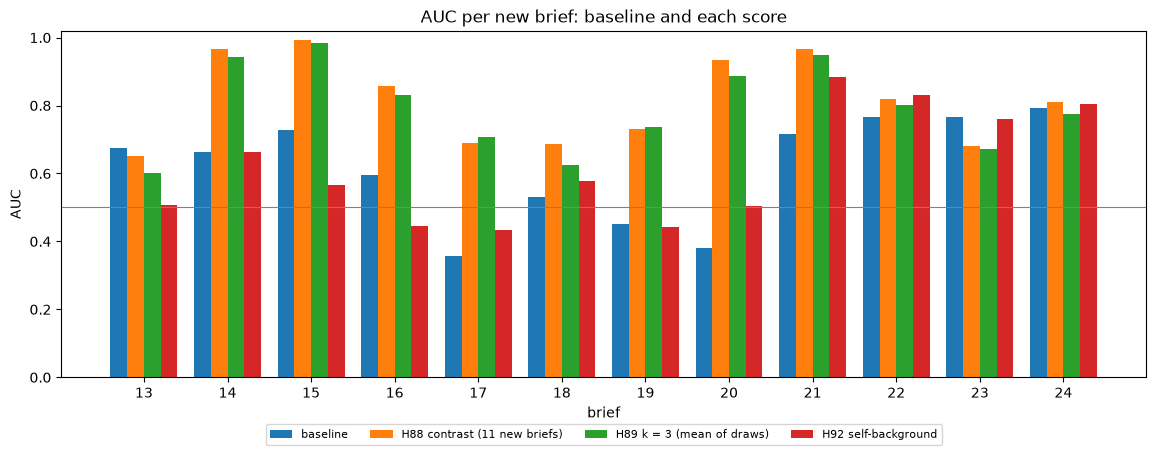

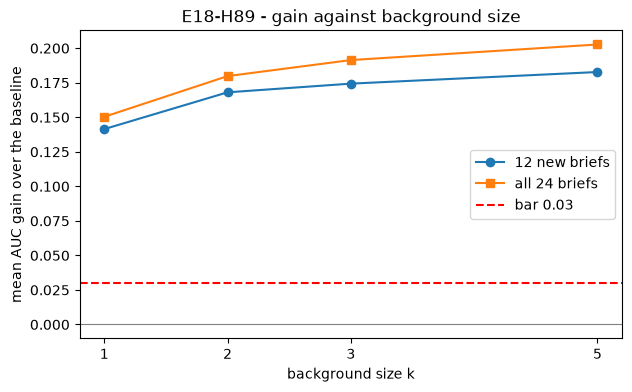

In [18]:
fig, ax = plt.subplots(figsize=(14, 4.5))
series = [("baseline", "baseline"), ("H88", "H88 contrast (11 new briefs)"), ("H89_k3", "H89 k = 3 (mean of draws)"), ("H92", "H92 self-background")]
width = 0.8 / len(series)
for k, (name, text) in enumerate(series):
    ax.bar(np.arange(12) + k * width, [AUC[name][b] for b in NEW_IDS], width, label=text)
ax.set_xticks(np.arange(12) + 0.4 - width / 2, [b[-2:] for b in NEW_IDS])
ax.set_xlabel("brief"); ax.set_ylabel("AUC"); ax.set_ylim(0.0, 1.02); ax.axhline(0.5, color="grey", lw=0.8)
ax.set_title("AUC per new brief: baseline and each score"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(H89_KS, [H89_TABLE[k]["new"]["mean_diff"] for k in H89_KS], marker="o", label="12 new briefs")
ax.plot(H89_KS, [H89_TABLE[k]["all24"]["mean_diff"] for k in H89_KS], marker="s", label="all 24 briefs")
ax.axhline(BAR_GAIN, color="red", ls="--", label=f"bar {BAR_GAIN}"); ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("background size k"); ax.set_ylabel("mean AUC gain over the baseline"); ax.set_xticks(list(H89_KS)); ax.legend()
ax.set_title("E18-H89 - gain against background size"); plt.show()

## Metrics JSON

Every measured number, the gate values, the bar clauses as value and boolean, and the verdict by bar are written to `reports/E18-contrast-replication-metrics.json`.

In [19]:
metrics = {
    "batch": "E18", "notebook": "B",
    "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"docdistance": docdistance.__version__, "python": platform.python_version(), "numpy": np.__version__, "POT": ot.__version__,
                    "encoder_backend": dd.backend, "reader": "default (auto by extension)", "DIFF_CHANGED_COST": DIFF_CHANGED_COST},
    "fixture_sha256": fixture_sha, "fixture_sha256_equals_registration": fixture_sha == REG["fixture_sha256"],
    "statement_counts": {"report": N_REPORT, "briefs": {b: len(BRIEF_TEXTS[b]) for b in ALL_IDS}, "controls": {c: len(CONTROL_TEXTS[c]) for c in CONTROL_IDS},
                         "section_groups": len(GROUPS)},
    "label_counts": {q: {"positives": int(l["pos"].sum()), "negatives": int(l["neg"].sum())} for q, l in LAB.items()}, "neutral_statements": int(IS_NEUTRAL.sum()),
    "harness_check": {"passed": HARNESS_PASSED, "largest_difference": HARNESS_MAX, "tolerance": HARNESS_TOL, "per_brief": HARNESS,
                      "controls_abs_diff": control_check},
    "auc_per_brief": {b: {n: AUC[n][b] for n in ALL_SCORES} for b in ALL_IDS},
    "auc_per_control": {c: {n: AUC[n][c] for n in SCORES} for c in CONTROL_IDS},
    "summary_new_briefs": SUMMARY_NEW, "summary_seen_briefs": SUMMARY_OLD, "summary_all_24_briefs": SUMMARY_ALL,
    "h89": {"draws": H89_DRAWS, "ks": list(H89_KS), "per_k": {str(k): H89_TABLE[k] for k in H89_KS}},
    "top2_section_share": SECTION_SHARE,
    "balanced_accuracy_per_brief": BA,
    "gates": {"batch": DECISION["batch_gate"], "E18-H90": DECISION["E18-H90"]["gate"]},
    "decisions": DECISION,
    "verdict_by_bar": {h: DECISION[h]["verdict_by_bar"] for h in ("E18-H88", "E18-H89", "E18-H90", "E18-H92")},
    "wall_seconds": round(time.time() - T_START, 1),
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")
console.print(f"written {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")
console.print(metrics["verdict_by_bar"])

written reports/E18-contrast-replication-metrics.json (33066 bytes)

{'E18-H88': 'Confirmed', 'E18-H89': 'Refuted', 'E18-H90': 'Confirmed', 'E18-H92': 'Refuted'}

## Conclusions

Verdicts are read on the registered bars only. The harness check passed with a largest absolute difference of 0.0 against the stored `E17` readings of briefs 01 to 12 (baseline and `E17-H85`, and the 7 controls). The batch gate passed: the baseline mean AUC over briefs 13 to 24 is 0.6183, below 0.95. The gate of `E18-H90` passed: the fixed cutoff 0.3253 reads a mean balanced accuracy of 0.5080, below 0.65, because it marks no statement as a match on 10 of the 12 new briefs and one statement on the other 2.

**E18-H88 - Confirmed.** With the other 11 new briefs as the background, the mean AUC rises from 0.6183 to 0.8158, a mean gain of +0.1975 (bootstrap 95% interval +0.1018 to +0.2961), against a bar of 0.03. The gain is above 0 in 10 of 12 new briefs, exactly at the bar of 10; briefs 13 (-0.0230) and 23 (-0.0851) lose. The control mean AUC rises from 0.6780 to 0.8596 (+0.1816), so the control clause holds. The registered prediction (gain of 0.10 or more, positive in 10 of 12) is met. Reported without a bar: with the 12 seen briefs as the background the gain is +0.1827 (9 of 12 briefs), with all 23 other briefs +0.1903 (10 of 12). The top-2 section share rises from 0.4167 to 0.7500. The gain is therefore also read on briefs `E17-H85` had not seen, of varied length and form; the count clause is met exactly at its bar (10 of 12), so one brief decides the verdict. The gain is smaller than on the seen briefs (+0.2474 with their own background).

**E18-H89 - Refuted.** At k = 3 the mean gain over the 12 new briefs is +0.1744, which meets the first clause, but the gain is above 0 in 9 of 12 briefs and the bar needs 10, so the bar is not met. Briefs 13, 23 and 24 lose at k = 1, 2, 3 and 5. The mean gain is +0.1414 at k = 1, +0.1681 at k = 2, +0.1744 at k = 3 and +0.1828 at k = 5, so most of the gain is already present with one background brief. The share of single draws with a gain above 0 is 0.7167, 0.7708, 0.7729 and 0.7854 for k = 1, 2, 3 and 5. Over all 24 briefs the count is 18 of 24 at k = 1, 2 and 3 and 19 of 24 at k = 5. The registered prediction was that the bar is met from k = 3; it is not, because of the count clause and not because of the size of the gain.

**E18-H90 - Confirmed.** The exact Otsu split of the contrast marks match with a mean balanced accuracy of 0.7243 over the 12 new briefs, against 0.5080 for the fixed cutoff, a difference of +0.2163; both clauses (at least 0.70, at least 0.10 above) hold. The split is above the fixed cutoff on all 12 new briefs, but five of them read below 0.70 (briefs 13, 17, 18, 19 and 23, between 0.6053 and 0.6842), and the mean is 0.0243 above the bar. On the seen briefs the same reading is 0.7366 (seen data, no bar). The Otsu split marks 7 to 53 statements as a match, where the targets hold 3 to 20: it separates the two groups of scores of a pair but does not follow the number of relevant statements.

**E18-H92 - Refuted.** Subtracting the mean nearest cost to the other sections of the report leaves the mean AUC at 0.6181 (mean difference -0.0002, bootstrap 95% interval -0.0608 to +0.0573), above 0 in 6 of 12 briefs against a bar of 10. Briefs 13, 14, 15, 16, 19 and 23 do not gain; briefs 13, 15 and 16 lose between 0.149 and 0.168. The control mean AUC rises by +0.1056, so only the control clause holds. On the seen briefs the difference is -0.0049 (5 of 12). The notebook does not isolate why the score does not rank. The registered risk (a section that restates another one lowers `g_i` of the statements it restates) is a possible reason and was not tested.

**What the fixture cannot show.** The report holds one broad topic in both parts, so a statement that is near every brief is common in this report; a report whose parts treat distinct subjects may behave differently. There is one report, and the 12 new briefs were written by the experimenter after the `E17` readings were known, so the briefs share an author with the seen set. The clause of `E18-H88` on the count sits exactly at the bar (10 of 12) and the clause of `E18-H89` one brief below it (9 of 12); a different brief would change both verdicts. The background of 11 briefs of one author is the registered case; the single-brief use named in the evidence is not read by `E18-H88`, `E18-H89` or `E18-H90`, which need other briefs, and the nearest the notebook comes to it is `E18-H89` at k = 1, with a mean gain of +0.1414 and 9 of 12 briefs above 0.